In [1]:
# %% [markdown]
# # Lab-to-Field Gap in Plant Disease Classification (PlantVillage -> PlantDoc), v2
# **Before you run (Kaggle setup):**
# 1. Settings: Accelerator = GPU T4 x1 (or P100), Internet = ON.
# 2. Add Data: `abdallahalidev/plantvillage-dataset` and the PlantDoc dataset (nirmalsankalana/plantdoc-dataset).
#    Optional: `puneet6060/intel-image-classification` (real backgrounds; otherwise synthetic backgrounds are used).
# 3. Step 2 has the switches: `QUICK` (smoke test), `RUN_ABLATION` (C4/C5), `RUN_UPPER_BOUND` (oracle).
# 4. Run top to bottom. First time: keep `QUICK = True` (about 10 min), then set it to `False`.
#
# **Conditions:** C0 baseline | C1 photometric | C2 background replacement | C3 = C1 + C2 + random erasing |
# C4 erasing only | C5 = C2 + erasing | UB = oracle with labelled field images.

# %% Step 1: Install and imports
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "grad-cam"], check=False)

import os, re, json, glob, random, time, shutil, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2
from PIL import Image
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm
import matplotlib.pyplot as plt
from scipy.stats import binomtest, wilcoxon
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
print("device:", DEVICE, "| torch", torch.__version__, "| timm", timm.__version__)

device: cuda | torch 2.11.0+cu130 | timm 1.0.30


In [2]:

# %% Step 2: Configuration (all switches are here)
QUICK = False              # True = smoke test, False = full experiment
RUN_ABLATION = True       # adds C4 and C5 (18 extra runs in full mode)
RUN_UPPER_BOUND = True    # adds the oracle UB runs (9 runs in full mode)
PRETRAINED = True         # needs Internet ON to download ImageNet weights

CFG = dict(
    models=["mobilenetv3_large_100", "efficientnet_b0", "resnet18"],
    #conds=["C0", "C1", "C2", "C3"] + (["C4", "C5"] if RUN_ABLATION else []),
    conds=["C0","C1","C2","C3"] + (["C4","C5","C6"] if RUN_ABLATION else []),
    seeds=[42, 123, 2024],
    epochs=6, bs=64, img=224, cap_per_class=400,
    lr_head=1e-3, lr_backbone=3e-4, wd=1e-4, workers=4,
)
if QUICK:
    CFG.update(models=["resnet18"], conds=["C0", "C2"], seeds=[42], epochs=2, cap_per_class=100, workers=2)
    RUN_UPPER_BOUND = False

OUT = Path("/kaggle/working") / ("quick" if QUICK else "full")
for d in ["preds", "ckpt", "figs"]:
    (OUT / d).mkdir(parents=True, exist_ok=True)

# Guard: resuming with different training settings would silently mix results
SIG = {k: CFG[k] for k in ["epochs", "bs", "img", "cap_per_class", "lr_head", "lr_backbone", "wd"]}
SIG_FILE = OUT / "config_signature.json"
if SIG_FILE.exists():
    old = json.load(open(SIG_FILE))
    assert old == SIG, f"Training settings changed since the saved results.\nsaved: {old}\nnow:   {SIG}\nDelete {OUT} to start fresh, or restore the old settings."
else:
    json.dump(SIG, open(SIG_FILE, "w"))

# Manual path overrides (leave None for auto-detect)
PV_COLOR, PV_SEG, BG_ROOT = None, None, None
PD_ROOT = Path("/kaggle/input/datasets/nirmalsankalana/plantdoc-dataset")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

norm = lambda s: re.sub(r"[^a-z0-9]", "", str(s).lower())
EXT = {".jpg", ".jpeg", ".png"}
def list_images(root):
    return [p for p in Path(root).rglob("*") if p.suffix.lower() in EXT]


In [3]:

# %% Step 3: Find the datasets
def walk_find(root, pred, maxdepth=5):
    hits = []
    for dp, dn, fn in os.walk(root):
        depth = len(Path(dp).relative_to(root).parts)
        if depth >= maxdepth: dn[:] = []
        if pred(Path(dp)): hits.append(Path(dp))
    return hits

ROOT = Path("/kaggle/input")
if PV_COLOR is None:
    hits = walk_find(ROOT, lambda p: p.name.lower() == "color")
    PV_COLOR = hits[0] if hits else None
if PV_SEG is None and PV_COLOR is not None and (PV_COLOR.parent / "segmented").exists():
    PV_SEG = PV_COLOR.parent / "segmented"
if PD_ROOT is None or not Path(PD_ROOT).exists():
    hits = walk_find(ROOT, lambda p: (p / "train").is_dir() and (p / "test").is_dir()
                     and "plantvillage" not in str(p).lower())
    PD_ROOT = hits[0] if hits else None
if BG_ROOT is None:
    hits = walk_find(ROOT, lambda p: "intelimageclassification" in norm(p.name))
    BG_ROOT = hits[0] if hits else None

print("PlantVillage color :", PV_COLOR)
print("PlantVillage segm. :", PV_SEG)
print("PlantDoc root      :", PD_ROOT)
print("Backgrounds        :", BG_ROOT, "(None -> synthetic backgrounds)")
assert PV_COLOR is not None, "PlantVillage not found: add abdallahalidev/plantvillage-dataset or set PV_COLOR"
assert PD_ROOT is not None, "PlantDoc not found: add the PlantDoc dataset or set PD_ROOT"


PlantVillage color : /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color
PlantVillage segm. : /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/segmented
PlantDoc root      : /kaggle/input/datasets/nirmalsankalana/plantdoc-dataset
Backgrounds        : None (None -> synthetic backgrounds)


In [4]:

# %% Step 4: Explore the datasets
seg_idx = {}
if PV_SEG is not None:
    for p in list_images(PV_SEG):
        seg_idx[(p.parent.name, re.sub(r"_final_masked$", "", p.stem.lower()))] = str(p)

df_pv = pd.DataFrame(
    [dict(path=str(p), cls=p.parent.name, seg=seg_idx.get((p.parent.name, p.stem.lower())))
     for p in list_images(PV_COLOR)])
df_pd = pd.DataFrame(
    [dict(path=str(p), raw=p.parent.name) for p in list_images(PD_ROOT)
     if p.parent.name.lower() not in ("train", "test", "val")])

print("PlantVillage images:", len(df_pv), "| classes:", df_pv.cls.nunique(),
      "| with segmented twin:", df_pv.seg.notna().mean().round(3))
print("PlantDoc images    :", len(df_pd), "| raw folders:", df_pd.raw.nunique())
print("\nPlantDoc folders:\n", df_pd.raw.value_counts().to_string())


PlantVillage images: 54305 | classes: 38 | with segmented twin: 0.978
PlantDoc images    : 2922 | raw folders: 28

PlantDoc folders:
 raw
Tomato_leaf_yellow_virus                238
Potato_leaf_late_blight                 208
Corn_leaf_blight                        194
Potato_leaf_early_blight                171
Tomato_Septoria_leaf_spot               157
Squash_Powdery_mildew_leaf              130
Raspberry_leaf                          119
Corn_rust_leaf                          117
Blueberry_leaf                          117
Peach_leaf                              112
Tomato_leaf_late_blight                 111
Tomato_leaf_bacterial_spot              110
Apple_rust_leaf                         106
Strawberry_leaf                          96
Apple_Scab_Leaf                          93
Tomato_mold_leaf                         91
Apple_leaf                               88
Tomato_Early_blight_leaf                 88
Bell_pepper_leaf_spot                    83
grape_leaf_black_rot      

In [5]:

# %% Step 5: Class mapping PlantDoc folder -> PlantVillage class
# Matching ignores case, spaces and punctuation.
PD2PV = {
    "Apple Scab Leaf": "Apple___Apple_scab",
    "Apple leaf": "Apple___healthy",
    "Apple rust leaf": "Apple___Cedar_apple_rust",
    "Bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot",
    "Bell_pepper leaf": "Pepper,_bell___healthy",
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn leaf blight": "Corn_(maize)___Northern_Leaf_Blight",
    "Corn rust leaf": "Corn_(maize)___Common_rust_",
    "Peach leaf": "Peach___healthy",
    "Potato leaf": "Potato___healthy",
    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",
    "Strawberry leaf": "Strawberry___healthy",
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "Tomato leaf": "Tomato___healthy",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold",
    "grape leaf black rot": "Grape___Black_rot",
    "grape leaf": "Grape___healthy",
    "squash Powdery mildew leaf": "Squash___Powdery_mildew",
    "Blueberry leaf": "Blueberry___healthy",
    "Cherry leaf": "Cherry_(including_sour)___healthy",
    "Raspberry leaf": "Raspberry___healthy",
    "Soyabean leaf": "Soybean___healthy",
}
pv_by_norm = {norm(c): c for c in df_pv.cls.unique()}
map_norm = {norm(k): norm(v) for k, v in PD2PV.items()}
df_pd["pv_cls"] = df_pd.raw.map(lambda r: pv_by_norm.get(map_norm.get(norm(r))))

print("PlantDoc folders NOT mapped :", sorted(df_pd[df_pd.pv_cls.isna()].raw.unique()))
print("Mapping entries with no PV class:",
      [k for k, v in PD2PV.items() if norm(v) not in pv_by_norm])

MIN_FIELD = 10
cnt = df_pd.dropna(subset=["pv_cls"]).groupby("pv_cls").size()
CLASSES = sorted(cnt[cnt >= MIN_FIELD].index)
cls2idx = {c: i for i, c in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)
print(f"\nFinal shared classes ({NUM_CLASSES}), field images per class:")
print(cnt[CLASSES].to_string())

df_pv = df_pv[df_pv.cls.isin(CLASSES)].copy(); df_pv["y"] = df_pv.cls.map(cls2idx)
df_fd = df_pd[df_pd.pv_cls.isin(CLASSES)].copy(); df_fd["y"] = df_fd.pv_cls.map(cls2idx)
pd.DataFrame({"plantvillage_class": CLASSES, "field_images": cnt[CLASSES].values}).to_csv(OUT / "mapping.csv", index=False)


PlantDoc folders NOT mapped : ['Tomato_two_spotted_spider_mites_leaf']
Mapping entries with no PV class: []

Final shared classes (27), field images per class:
pv_cls
Apple___Apple_scab                                     93
Apple___Cedar_apple_rust                              106
Apple___healthy                                        88
Blueberry___healthy                                   117
Cherry_(including_sour)___healthy                      57
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     67
Corn_(maize)___Common_rust_                           117
Corn_(maize)___Northern_Leaf_Blight                   194
Grape___Black_rot                                      79
Grape___healthy                                        75
Peach___healthy                                       112
Pepper,_bell___Bacterial_spot                          83
Pepper,_bell___healthy                                 42
Potato___Early_blight                                 171
Potato___Late_blight 

In [6]:

# %% Step 6: Splits (PV 80/20 with cap per class; PlantDoc 30% field-val / 70% field-test)
tr, va = [], []
for c, g in df_pv.groupby("cls"):
    g = g.sample(min(len(g), CFG["cap_per_class"]), random_state=0)
    a, b = train_test_split(g, test_size=0.2, random_state=0)
    tr.append(a); va.append(b)
df_tr, df_va = pd.concat(tr), pd.concat(va)
df_fv, df_ft = train_test_split(df_fd, test_size=0.7, stratify=df_fd.y, random_state=42)

for n, d in [("pv_train", df_tr), ("pv_val", df_va), ("field_val", df_fv), ("field_test", df_ft)]:
    d.to_csv(OUT / f"{n}.csv", index=False)
    print(f"{n:11s}: {len(d)}")
# RULE: field_test is used ONLY for final reporting. Never tune on it.


pv_train   : 8462
pv_val     : 2117
field_val  : 876
field_test : 2044


real background images: 0


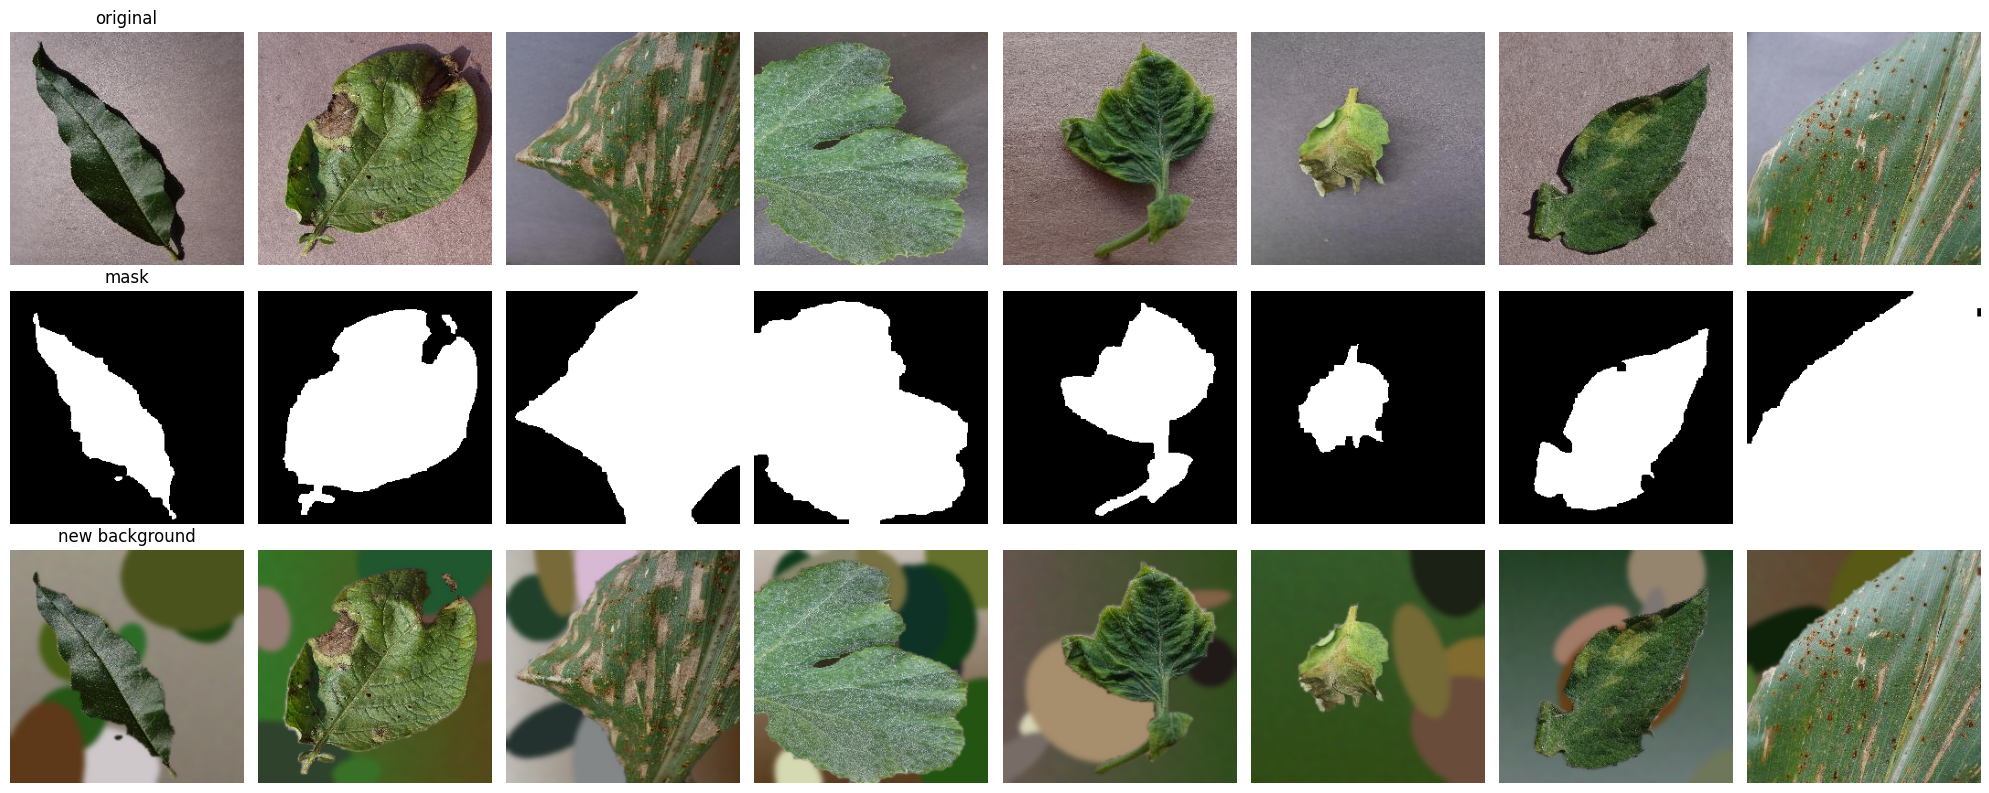

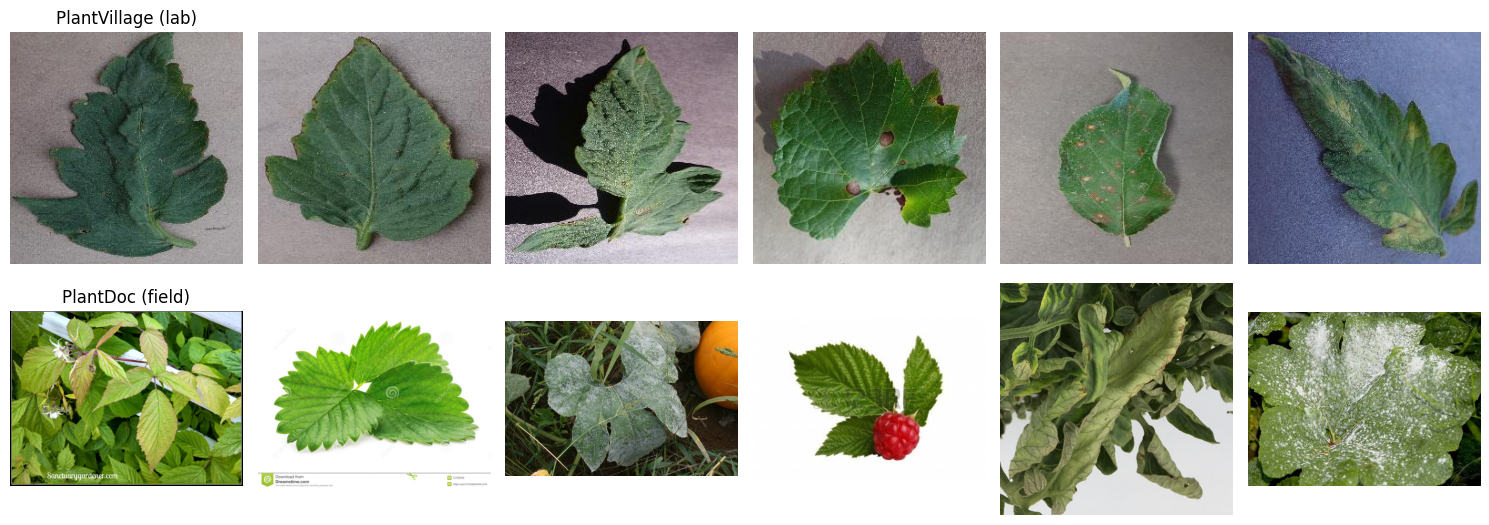

In [7]:

# %% Step 7: Background replacement module (eroded mask + soft edge + earthy synthetic backgrounds)
def hsv_mask(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    m = cv2.inRange(hsv, (10, 25, 25), (100, 255, 255))
    return cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8)) > 0

def leaf_mask(rgb, seg_path=None):
    if isinstance(seg_path, str):
        s = cv2.imread(seg_path)
        if s is not None:
            if s.shape[:2] != rgb.shape[:2]:
                s = cv2.resize(s, (rgb.shape[1], rgb.shape[0]))
            m = (cv2.cvtColor(s, cv2.COLOR_BGR2GRAY) > 10).astype(np.uint8)
            m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
            m = cv2.erode(m, np.ones((3, 3), np.uint8), iterations=1)   # removes the pale edge fringe
            return m > 0
    return hsv_mask(rgb)

BG_PATHS = []
if BG_ROOT is not None:
    BG_PATHS = [str(p) for p in list_images(BG_ROOT)]
    random.Random(0).shuffle(BG_PATHS); BG_PATHS = BG_PATHS[:1500]
print("real background images:", len(BG_PATHS))

EARTH = np.array([[34,70,30],[60,100,40],[90,70,40],[120,95,60],
                  [150,140,120],[110,110,105],[200,200,195],[30,45,25]])
def synthetic_bg(h, w):
    rng = np.random.default_rng(random.getrandbits(32))
    pick = lambda: np.clip(EARTH[rng.integers(0, len(EARTH))] + rng.integers(-20, 20, 3), 0, 255)
    c1, c2 = pick(), pick()
    t = np.linspace(0, 1, h)[:, None, None] if rng.random() < .5 else np.linspace(0, 1, w)[None, :, None]
    bg = np.clip(np.zeros((h, w, 3)) + c1 * (1 - t) + c2 * t + rng.normal(0, 12, (h, w, 3)), 0, 255).astype(np.uint8)
    for _ in range(int(rng.integers(4, 10))):
        cv2.ellipse(bg, (int(rng.integers(0, w)), int(rng.integers(0, h))),
                    (int(rng.integers(10, w // 3)), int(rng.integers(10, h // 3))),
                    float(rng.integers(0, 180)), 0, 360, tuple(int(v) for v in pick()), -1)
    return cv2.GaussianBlur(bg, (0, 0), 3)

def random_bg(h, w):
    if BG_PATHS:
        b = cv2.imread(random.choice(BG_PATHS))
        if b is not None:
            return cv2.resize(cv2.cvtColor(b, cv2.COLOR_BGR2RGB), (w, h))
    return synthetic_bg(h, w)

def replace_bg(pil, seg_path=None, p=0.5):
    if random.random() > p: return pil
    rgb = np.array(pil); h, w = rgb.shape[:2]
    m = leaf_mask(rgb, seg_path)
    if m.mean() < 0.05 or m.mean() > 0.98:      # mask failed: keep the original
        return pil
    alpha = cv2.GaussianBlur(m.astype(np.float32), (0, 0), 1.0)[..., None]   # soft edge
    out = alpha * rgb + (1 - alpha) * random_bg(h, w)
    return Image.fromarray(np.clip(out, 0, 255).astype(np.uint8))

# Visual check (look at this figure before training!)
fig, ax = plt.subplots(3, 8, figsize=(20, 8))
samp = df_tr.sample(8, random_state=1)
for j, (_, r) in enumerate(samp.iterrows()):
    im = Image.open(r.path).convert("RGB")
    ax[0, j].imshow(im); ax[0, j].axis("off")
    ax[1, j].imshow(leaf_mask(np.array(im), r.seg), cmap="gray"); ax[1, j].axis("off")
    ax[2, j].imshow(replace_bg(im, r.seg, p=1.0)); ax[2, j].axis("off")
ax[0, 0].set_title("original"); ax[1, 0].set_title("mask"); ax[2, 0].set_title("new background")
plt.tight_layout(); plt.savefig(OUT / "figs/bg_check.png", dpi=120); plt.show()

# Lab vs field samples (Figure 1 of the paper)
fig, ax = plt.subplots(2, 6, figsize=(15, 5.5))
for j, (_, r) in enumerate(df_tr.sample(6, random_state=2).iterrows()):
    ax[0, j].imshow(Image.open(r.path)); ax[0, j].axis("off")
for j, (_, r) in enumerate(df_ft.sample(6, random_state=2).iterrows()):
    ax[1, j].imshow(Image.open(r.path)); ax[1, j].axis("off")
ax[0, 0].set_title("PlantVillage (lab)"); ax[1, 0].set_title("PlantDoc (field)")
plt.tight_layout(); plt.savefig(OUT / "figs/lab_vs_field.png", dpi=150); plt.show()


In [8]:

# %% Step 8: Datasets, transforms, conditions
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
NORM = T.Normalize(MEAN, STD)
EVAL_TF = T.Compose([T.ToTensor(), NORM])
#BG_P = {"C0": 0.0, "C1": 0.0, "C2": 0.5, "C3": 0.5, "C4": 0.0, "C5": 0.5, "UB": 0.0}
BG_P = {"C0": 0.0, "C1": 0.0, "C2": 0.5, "C3": 0.5, "C4": 0.0, "C5": 0.5,"C6": 0.5, "UB": 0.0}
def build_tf(cond):
    ops = [T.Resize((CFG["img"], CFG["img"])), T.RandomHorizontalFlip(), T.RandomRotation(20)]
    if cond in ("C1", "C3","C6"):
        ops += [T.ColorJitter(0.4, 0.4, 0.4, 0.1), T.RandomApply([T.GaussianBlur(5, (0.1, 2.0))], p=0.2)]
    ops += [T.ToTensor(), NORM]
    if cond in ("C3", "C4", "C5"):
        ops += [T.RandomErasing(p=0.3, scale=(0.02, 0.15))]
    return T.Compose(ops)

class TrainDS(Dataset):
    def __init__(self, df, tf, bg_p):
        self.rows, self.tf, self.bg_p = df.to_dict("records"), tf, bg_p
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        r = self.rows[i]
        img = Image.open(r["path"]).convert("RGB")
        if self.bg_p > 0: img = replace_bg(img, r["seg"], self.bg_p)
        return self.tf(img), int(r["y"])

class CachedDS(Dataset):      # evaluation sets, preloaded once at 224x224
    def __init__(self, df, size=224):
        self.imgs = [Image.open(p).convert("RGB").resize((size, size), Image.BILINEAR) for p in df.path]
        self.y = df.y.values
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i): return EVAL_TF(self.imgs[i]), int(self.y[i])

pv_val_ds, field_test_ds = CachedDS(df_va), CachedDS(df_ft)
np.save(OUT / "preds/field_labels.npy", field_test_ds.y)
print("eval sets cached:", len(pv_val_ds), len(field_test_ds))


eval sets cached: 2117 2044


In [9]:

# %% Step 9: Model, training and evaluation functions
def make_model(name, n=None, pretrained=PRETRAINED):
    return timm.create_model(name, pretrained=pretrained, num_classes=n or NUM_CLASSES)

@torch.no_grad()
def predict(model, ds):
    model.eval(); P = []
    for x, _ in DataLoader(ds, batch_size=128, shuffle=False, num_workers=0):
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=USE_AMP):
            P.append(model(x.to(DEVICE)).argmax(1).cpu())
    return torch.cat(P).numpy()

def run_one(mname, cond, seed):
    t0 = time.time(); set_seed(seed)
    g = torch.Generator(); g.manual_seed(seed)
    dl = DataLoader(TrainDS(df_tr, build_tf(cond), BG_P[cond]), batch_size=CFG["bs"], shuffle=True,
                    num_workers=CFG["workers"], drop_last=True, pin_memory=USE_AMP,
                    persistent_workers=CFG["workers"] > 0, generator=g)
    model = make_model(mname).to(DEVICE)
    head_ids = {id(p) for p in model.get_classifier().parameters()}
    head = [p for p in model.parameters() if id(p) in head_ids]
    back = [p for p in model.parameters() if id(p) not in head_ids]
    opt = torch.optim.AdamW([{"params": back, "lr": CFG["lr_backbone"]},
                             {"params": head, "lr": CFG["lr_head"]}], weight_decay=CFG["wd"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["epochs"] * len(dl))
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    crit = nn.CrossEntropyLoss()
    for ep in range(CFG["epochs"]):
        model.train(); tot = 0
        for x, y in dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=USE_AMP):
                loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item()
        print(f"   epoch {ep+1}/{CFG['epochs']} loss {tot/len(dl):.4f}")
    pv_pred, fd_pred = predict(model, pv_val_ds), predict(model, field_test_ds)
    np.save(OUT / f"preds/{mname}_{cond}_{seed}.npy", fd_pred)
    if seed == CFG["seeds"][0]:
        torch.save(model.state_dict(), OUT / f"ckpt/{mname}_{cond}.pt")
    res = dict(model=mname, cond=cond, seed=seed,
               pv_val_acc=accuracy_score(pv_val_ds.y, pv_pred),
               pv_val_f1=f1_score(pv_val_ds.y, pv_pred, average="macro"),
               field_acc=accuracy_score(field_test_ds.y, fd_pred),
               field_f1=f1_score(field_test_ds.y, fd_pred, average="macro"),
               minutes=round((time.time() - t0) / 60, 2))
    res["gap"] = res["pv_val_acc"] - res["field_acc"]
    del model, opt; torch.cuda.empty_cache()
    return res


In [ ]:

# %% Step 10: Run the main experiments (resumable; results saved after every run)
RES_FILE = OUT / "results.json"
results = json.load(open(RES_FILE)) if RES_FILE.exists() else []
done = {(r["model"], r["cond"], r["seed"]) for r in results}
total = len(CFG["models"]) * len(CFG["conds"]) * len(CFG["seeds"])
k = 0
for m in CFG["models"]:
    for c in CFG["conds"]:
        for s in CFG["seeds"]:
            k += 1
            if (m, c, s) in done: continue
            print(f"[{k}/{total}] {m} | {c} | seed {s}")
            r = run_one(m, c, s); results.append(r)
            json.dump(results, open(RES_FILE, "w"), indent=1)
            print(f"   -> PV-val {r['pv_val_acc']:.3f} | FIELD {r['field_acc']:.3f} | gap {r['gap']:.3f} | {r['minutes']} min")


[1/63] mobilenetv3_large_100 | C0 | seed 42


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.1MB            

model.safetensors: downloading bytes:           |  0.00B            

   epoch 1/6 loss 0.4284
   epoch 2/6 loss 0.0459
   epoch 3/6 loss 0.0230
   epoch 4/6 loss 0.0133
   epoch 5/6 loss 0.0067
   epoch 6/6 loss 0.0050
   -> PV-val 0.988 | FIELD 0.166 | gap 0.821 | 2.85 min
[2/63] mobilenetv3_large_100 | C0 | seed 123
   epoch 1/6 loss 0.4201
   epoch 2/6 loss 0.0593
   epoch 3/6 loss 0.0189
   epoch 4/6 loss 0.0086
   epoch 5/6 loss 0.0067
   epoch 6/6 loss 0.0047
   -> PV-val 0.991 | FIELD 0.186 | gap 0.805 | 1.74 min
[3/63] mobilenetv3_large_100 | C0 | seed 2024
   epoch 1/6 loss 0.4346
   epoch 2/6 loss 0.0422
   epoch 3/6 loss 0.0228
   epoch 4/6 loss 0.0125
   epoch 5/6 loss 0.0073
   epoch 6/6 loss 0.0052
   -> PV-val 0.985 | FIELD 0.192 | gap 0.793 | 1.73 min
[4/63] mobilenetv3_large_100 | C1 | seed 42
   epoch 1/6 loss 0.5970
   epoch 2/6 loss 0.1052
   epoch 3/6 loss 0.0513
   epoch 4/6 loss 0.0361
   epoch 5/6 loss 0.0236
   epoch 6/6 loss 0.0226
   -> PV-val 0.983 | FIELD 0.183 | gap 0.800 | 3.33 min
[5/63] mobilenetv3_large_100 | C1 | seed 

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

   epoch 1/6 loss 0.4565
   epoch 2/6 loss 0.0440
   epoch 3/6 loss 0.0212
   epoch 4/6 loss 0.0094
   epoch 5/6 loss 0.0051
   epoch 6/6 loss 0.0043
   -> PV-val 0.989 | FIELD 0.151 | gap 0.837 | 2.64 min
[23/63] efficientnet_b0 | C0 | seed 123
   epoch 1/6 loss 0.4322
   epoch 2/6 loss 0.0482
   epoch 3/6 loss 0.0186
   epoch 4/6 loss 0.0079
   epoch 5/6 loss 0.0056
   epoch 6/6 loss 0.0044
   -> PV-val 0.987 | FIELD 0.170 | gap 0.817 | 2.59 min
[24/63] efficientnet_b0 | C0 | seed 2024
   epoch 1/6 loss 0.4360
   epoch 2/6 loss 0.0378
   epoch 3/6 loss 0.0204
   epoch 4/6 loss 0.0085
   epoch 5/6 loss 0.0054
   epoch 6/6 loss 0.0035
   -> PV-val 0.988 | FIELD 0.165 | gap 0.823 | 2.59 min
[25/63] efficientnet_b0 | C1 | seed 42
   epoch 1/6 loss 0.5853
   epoch 2/6 loss 0.0893
   epoch 3/6 loss 0.0505
   epoch 4/6 loss 0.0288
   epoch 5/6 loss 0.0192
   epoch 6/6 loss 0.0158
   -> PV-val 0.986 | FIELD 0.179 | gap 0.808 | 3.55 min
[26/63] efficientnet_b0 | C1 | seed 123
   epoch 1/6 los

In [ ]:
RES_FILE = OUT / "results.json"
bad = "mobilenetv3_large_100"
res = [r for r in json.load(open(RES_FILE)) if not (r["model"] == bad and r["cond"] == "C1")]
json.dump(res, open(RES_FILE, "w"), indent=1)
for f in (OUT / "preds").glob(f"{bad}_C1_*.npy"): f.unlink()
for f in (OUT / "ckpt").glob(f"{bad}_C1.pt"): f.unlink()
print("remaining results:", len(res))

In [ ]:

# %% Step 11: Oracle upper bound (PlantVillage + labelled field_val images, oversampled x4)
# Shows how much real field data helps beyond augmentation. Skipped when RUN_UPPER_BOUND = False.
if RUN_UPPER_BOUND:
    results = json.load(open(RES_FILE))
    df_tr_orig = df_tr
    df_tr = pd.concat([df_tr_orig] + [df_fv.assign(seg=None)] * 4, ignore_index=True)
    print("UB training images:", len(df_tr))
    try:
        for m in CFG["models"]:
            for s in CFG["seeds"]:
                if any(r["model"] == m and r["cond"] == "UB" and r["seed"] == s for r in results): continue
                print(f"UB | {m} | seed {s}")
                r = run_one(m, "UB", s); results.append(r)
                json.dump(results, open(RES_FILE, "w"), indent=1)
                print(f"   -> PV-val {r['pv_val_acc']:.3f} | FIELD {r['field_acc']:.3f} | {r['minutes']} min")
    finally:
        df_tr = df_tr_orig          # always restore the clean training set
else:
    print("Upper bound skipped.")


In [ ]:
import itertools
conds = CFG["conds"] + (["UB"] if RUN_UPPER_BOUND else [])
found = 0
for m in CFG["models"]:
    for s in CFG["seeds"]:
        P = {}
        for c in conds:
            f = OUT / f"preds/{m}_{c}_{s}.npy"
            if f.exists(): P[c] = np.load(f)
            else: print("missing:", f.name)
        for a, b in itertools.combinations(P, 2):
            if np.array_equal(P[a], P[b]):
                print("IDENTICAL predictions:", m, s, a, "==", b); found += 1
print("duplicate check done | identical pairs found:", found)

In [ ]:

# %% Step 12: Table A (mean +/- std over seeds), gains and gap reduction
df = pd.DataFrame(json.load(open(RES_FILE)))
g = df.groupby(["model", "cond"])
A = g.agg(pv_acc=("pv_val_acc", "mean"), pv_sd=("pv_val_acc", "std"),
          fd_acc=("field_acc", "mean"), fd_sd=("field_acc", "std"),
          fd_f1=("field_f1", "mean"), fd_f1_sd=("field_f1", "std"),
          gap=("gap", "mean")).fillna(0).reset_index()
mo = {m: i for i, m in enumerate(CFG["models"])}
A["_o"] = A.model.map(mo); A = A.sort_values(["_o", "cond"]).drop(columns="_o").reset_index(drop=True)
base = A[A.cond == "C0"].set_index("model")
A["gain_pp"] = [(r.fd_acc - base.fd_acc[r.model]) * 100 for r in A.itertuples()]
A["rel_gain_%"] = [100 * (r.fd_acc / base.fd_acc[r.model] - 1) for r in A.itertuples()]
A["gap_reduction_%"] = [100 * (base.gap[r.model] - r.gap) / base.gap[r.model] for r in A.itertuples()]
tableA = pd.DataFrame({
    "Model": A.model, "Condition": A.cond,
    "PV-val Acc": [f"{a*100:.2f} ± {b*100:.2f}" for a, b in zip(A.pv_acc, A.pv_sd)],
    "Field Acc": [f"{a*100:.2f} ± {b*100:.2f}" for a, b in zip(A.fd_acc, A.fd_sd)],
    "Field macro-F1": [f"{a*100:.2f} ± {b*100:.2f}" for a, b in zip(A.fd_f1, A.fd_f1_sd)],
    "Gap (pp)": (A.gap * 100).round(2),
    "Field gain (pp)": A.gain_pp.round(2),
    "Field gain (rel %)": A["rel_gain_%"].round(1),
    "Gap reduction %": A["gap_reduction_%"].round(1)})
tableA.to_csv(OUT / "tableA_main.csv", index=False)
print(tableA.to_string(index=False))
print("\n(std is the sample std over", len(CFG["seeds"]), "seeds)")


In [ ]:

# %% Step 13: Significance. Table C (first seed: McNemar + bootstrap CI), Table C2 (all seeds, Holm-corrected)
y = np.load(OUT / "preds/field_labels.npy"); S0 = CFG["seeds"][0]
AUG = [c for c in CFG["conds"] if c != "C0"]
rng = np.random.default_rng(0)

def mcnemar_p(ok0, okc):
    b, cc = int((ok0 & ~okc).sum()), int((~ok0 & okc).sum())
    return 1.0 if b + cc == 0 else binomtest(b, b + cc, 0.5).pvalue

def holm(ps):
    ps = np.asarray(ps, float); order = np.argsort(ps); m = len(ps)
    adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * ps[i]); adj[i] = min(1.0, run)
    return adj

rows = []
for m in CFG["models"]:
    p0 = np.load(OUT / f"preds/{m}_C0_{S0}.npy")
    for c in AUG:
        pc = np.load(OUT / f"preds/{m}_{c}_{S0}.npy"); ok0, okc = p0 == y, pc == y
        idx = rng.integers(0, len(y), (2000, len(y)))
        d = okc[idx].mean(1) - ok0[idx].mean(1)
        lo, hi = np.percentile(d, [2.5, 97.5])
        rows.append(dict(model=m, comparison=f"{c} vs C0", acc_diff_pp=round((okc.mean() - ok0.mean()) * 100, 2),
                         CI95_pp=f"[{lo*100:.2f}, {hi*100:.2f}]", mcnemar_p=mcnemar_p(ok0, okc)))
tableC = pd.DataFrame(rows); tableC["p_holm"] = holm(tableC.mcnemar_p)
tableC.to_csv(OUT / "tableC_significance.csv", index=False)
print(f"Table C (seed {S0}):"); print(tableC.round(4).to_string(index=False))

rows = []
for m in CFG["models"]:
    for c in AUG:
        for s in CFG["seeds"]:
            p0 = np.load(OUT / f"preds/{m}_C0_{s}.npy"); pc = np.load(OUT / f"preds/{m}_{c}_{s}.npy")
            ok0, okc = p0 == y, pc == y
            rows.append(dict(model=m, cond=c, seed=s, diff_pp=100 * (okc.mean() - ok0.mean()),
                             p=mcnemar_p(ok0, okc)))
per = pd.DataFrame(rows); per["p_holm"] = holm(per.p)
C2 = per.groupby(["model", "cond"]).agg(
    mean_diff_pp=("diff_pp", "mean"), min_diff_pp=("diff_pp", "min"),
    seeds_sig_holm=("p_holm", lambda s: int((s < 0.05).sum()))).round(2).reset_index()
C2.to_csv(OUT / "tableC2_per_seed_holm.csv", index=False)
print(f"\nTable C2 (each seed vs C0, Holm over {len(per)} tests; seeds_sig_holm out of {len(CFG['seeds'])}):")
print(C2.to_string(index=False))


In [ ]:

# %% Step 14: Table B, efficiency (params, GFLOPs, size, latency)
from torch.utils.flop_counter import FlopCounterMode
def latency(model, device, n=100):
    x = torch.randn(1, 3, 224, 224).to(device); model = model.to(device).eval()
    with torch.no_grad():
        for _ in range(20): model(x)
        if device == "cuda": torch.cuda.synchronize()
        t = time.time()
        for _ in range(n): model(x)
        if device == "cuda": torch.cuda.synchronize()
    return (time.time() - t) / n * 1000

rows = []
for m in CFG["models"]:
    net = make_model(m, NUM_CLASSES, pretrained=False).eval()
    with FlopCounterMode(display=False) as fc, torch.no_grad():
        net(torch.randn(1, 3, 224, 224))
    P = sum(p.numel() for p in net.parameters())
    rows.append(dict(model=m, params_M=round(P / 1e6, 2), GFLOPs=round(fc.get_total_flops() / 1e9, 2),
                     size_MB=round(P * 4 / 1e6, 1), cpu_ms=round(latency(net, "cpu"), 1),
                     gpu_ms=round(latency(net, "cuda"), 1) if DEVICE == "cuda" else None))
tableB = pd.DataFrame(rows); tableB.to_csv(OUT / "tableB_efficiency.csv", index=False)
print(tableB.to_string(index=False))
print("Setup: batch 1, 224x224, 100 runs after 20 warm-up runs; CPU = Kaggle CPU; GPU =", 
      torch.cuda.get_device_name(0) if DEVICE == "cuda" else "n/a")


In [ ]:

# %% Step 15: Figures (gap chart, confusion matrices, accuracy vs latency)
labels = [f"{m.split('_')[0]}\n{c}" for m, c in zip(A.model, A.cond)]
x = np.arange(len(A)); w = 0.38
plt.figure(figsize=(max(8, len(A) * 0.8), 5))
plt.bar(x - w/2, A.pv_acc * 100, w, yerr=A.pv_sd * 100, label="PlantVillage val (lab)", capsize=3)
plt.bar(x + w/2, A.fd_acc * 100, w, yerr=A.fd_sd * 100, label="PlantDoc test (field)", capsize=3)
plt.xticks(x, labels, fontsize=7); plt.ylabel("Accuracy (%)"); plt.legend(); plt.title("Lab-to-field gap")
plt.tight_layout(); plt.savefig(OUT / "figs/gap_chart.png", dpi=200); plt.show()

A_aug = A[A.cond != "UB"]
best = A_aug.sort_values("fd_acc", ascending=False).iloc[0]
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
for a, c in zip(ax, ["C0", best.cond]):
    pr = np.load(OUT / f"preds/{best.model}_{c}_{S0}.npy")
    cm = confusion_matrix(y, pr, labels=range(NUM_CLASSES), normalize="true")
    a.imshow(cm, cmap="Blues", vmin=0, vmax=1); a.set_title(f"{best.model} | {c} (field test)")
    a.set_xlabel("Predicted class index"); a.set_ylabel("True class index")
plt.tight_layout(); plt.savefig(OUT / "figs/confusion.png", dpi=200); plt.show()

lat = tableB.set_index("model").cpu_ms
plt.figure(figsize=(7, 5))
for _, r in A_aug.iterrows():
    plt.scatter(lat[r.model], r.fd_acc * 100, s=60)
    plt.annotate(f"{r.model.split('_')[0]}-{r.cond}", (lat[r.model], r.fd_acc * 100), fontsize=7)
plt.xlabel("CPU latency (ms/img)"); plt.ylabel("Field accuracy (%)"); plt.title("Accuracy vs latency")
plt.tight_layout(); plt.savefig(OUT / "figs/acc_vs_latency.png", dpi=200); plt.show()


In [ ]:

# %% Step 16: Grad-CAM + foliage attention ratio (C0 vs C3, predicted class)
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

GM = "efficientnet_b0" if "efficientnet_b0" in CFG["models"] else CFG["models"][0]
ALT = "C3" if "C3" in CFG["conds"] else CFG["conds"][-1]

def load(cond):
    m = make_model(GM, NUM_CLASSES, pretrained=False)
    m.load_state_dict(torch.load(OUT / f"ckpt/{GM}_{cond}.pt", map_location="cpu"))
    return m.to(DEVICE).eval()

def target_layers(m): return [m.layer4[-1]] if GM.startswith("resnet") else [m.blocks[-1]]

def grabcut_mask(rgb):
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR); m = np.zeros(bgr.shape[:2], np.uint8)
    h, w = m.shape
    try:
        cv2.grabCut(bgr, m, (int(.1*w), int(.1*h), int(.8*w), int(.8*h)),
                    np.zeros((1, 65)), np.zeros((1, 65)), 3, cv2.GC_INIT_WITH_RECT)
    except Exception:
        return None
    mk = ((m == 1) | (m == 3)).astype(np.float32)
    return mk if 0.05 < mk.mean() < 0.95 else None

models_cam = {c: load(c) for c in ["C0", ALT]}
cams = {c: GradCAM(model=models_cam[c], target_layers=target_layers(models_cam[c])) for c in models_cam}

N = min(60, len(field_test_ds))
idx = np.random.RandomState(0).choice(len(field_test_ds), N, replace=False)
ratio = {c: [] for c in cams}; shown = []
for i in idx:
    rgb = np.array(field_test_ds.imgs[i]); mk = grabcut_mask(rgb)
    if mk is None: continue
    xt = EVAL_TF(field_test_ds.imgs[i]).unsqueeze(0).to(DEVICE)
    maps = {}
    for c, cam in cams.items():
        hm = cam(input_tensor=xt, targets=None)[0]
        maps[c] = hm; ratio[c].append(float((hm * mk).sum() / (hm.sum() + 1e-8)))
    if len(shown) < 6: shown.append((rgb, maps))

print(f"model: {GM} (seed {S0}) | images used (valid GrabCut mask): {len(ratio['C0'])}")
for c in ratio: print(f"mean foliage-attention ratio {c}: {np.mean(ratio[c]):.3f} ± {np.std(ratio[c]):.3f}")
if len(ratio["C0"]) > 5:
    print(f"Wilcoxon p (C0 vs {ALT}):", wilcoxon(ratio["C0"], ratio[ALT]).pvalue)
print("NOTE: GrabCut mask is an approximation and Grad-CAM explains the PREDICTED class; treat as a proxy.")

fig, ax = plt.subplots(3, len(shown), figsize=(3 * len(shown), 9))
for j, (rgb, maps) in enumerate(shown):
    ax[0, j].imshow(rgb)
    ax[1, j].imshow(show_cam_on_image(rgb / 255.0, maps["C0"], use_rgb=True))
    ax[2, j].imshow(show_cam_on_image(rgb / 255.0, maps[ALT], use_rgb=True))
    for r in range(3): ax[r, j].axis("off")
ax[0, 0].set_title("field image"); ax[1, 0].set_title("Grad-CAM C0"); ax[2, 0].set_title(f"Grad-CAM {ALT}")
plt.tight_layout(); plt.savefig(OUT / "figs/gradcam.png", dpi=200); plt.show()


In [ ]:

# %% Step 17: Per-class F1 and top confusions (to verify the confusion-matrix story)
short = [c.replace("_(maize)", "").replace("_(including_sour)", "").replace("___", " | ") for c in CLASSES]
res = {}
for c in ["C0", ALT]:
    pr = np.load(OUT / f"preds/{GM}_{c}_{S0}.npy")
    _, _, f1, sup = precision_recall_fscore_support(y, pr, labels=range(NUM_CLASSES), zero_division=0)
    res[c] = (pr, f1)
pc_tab = pd.DataFrame({"class": short, "support": sup,
                       "F1_C0": res["C0"][1].round(3), f"F1_{ALT}": res[ALT][1].round(3)})
pc_tab["delta"] = (pc_tab[f"F1_{ALT}"] - pc_tab["F1_C0"]).round(3)
pc_tab.sort_values("delta").to_csv(OUT / "table_per_class_f1.csv", index=False)
print(f"Per-class F1, {GM}: C0 vs {ALT} (sorted by change)")
print(pc_tab.sort_values("delta").to_string(index=False))

for c in ["C0", ALT]:
    pr = res[c][0]
    cm = confusion_matrix(y, pr, labels=range(NUM_CLASSES)); np.fill_diagonal(cm, 0)
    top = np.dstack(np.unravel_index(np.argsort(cm.ravel())[::-1][:8], cm.shape))[0]
    print(f"\nTop confusions ({c}): true -> predicted (count)")
    for t, p in top: print(f"  {short[t]}  ->  {short[p]}  ({cm[t, p]})")
    sink = pd.Series(pr).value_counts().head(5)
    print(f"Most-predicted classes ({c}):", {short[i]: int(n) for i, n in sink.items()})


In [ ]:

# %% Step 18: Package the results (tables, figures, predictions; checkpoints excluded)
zip_path = Path("/kaggle/working") / f"results_{OUT.name}.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file() and "ckpt" not in p.parts:
            z.write(p, p.relative_to(OUT.parent))
print("Saved:", zip_path, f"({zip_path.stat().st_size/1e6:.1f} MB)")
for p in sorted(OUT.rglob("*")):
    if p.is_file() and p.suffix in {".csv", ".png", ".json"}: print(p)
# Download the zip from the Output panel (or click Save Version -> Save & Run All).

In [ ]:
# %% Step 19: Training curves (accuracy and loss per epoch, paper-style figure)
# Run AFTER Steps 1-9 in the same session (it needs df_tr, build_tf, BG_P, TrainDS, make_model,
# pv_val_ds, field_test_ds, CFG, OUT). It does NOT touch results.json, preds or ckpt.
import torch.nn.functional as F

CURVE_EPOCHS = 15            # more points = smoother curve. Use CFG["epochs"] (6) to match Table A exactly.
CURVE_SEED = CFG["seeds"][0]
_cm = "efficientnet_b0" if "efficientnet_b0" in CFG["models"] else CFG["models"][0]
CURVE_RUNS = [(_cm, "C0"), (_cm, "C3" if "C3" in CFG["conds"] else CFG["conds"][-1])]
(OUT / "history").mkdir(exist_ok=True)

@torch.no_grad()
def eval_loss_acc(model, ds):
    model.eval(); loss_sum, correct = 0.0, 0
    for x, y in DataLoader(ds, batch_size=256, shuffle=False, num_workers=0):
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=USE_AMP):
            out = model(x)
        loss_sum += F.cross_entropy(out.float(), y, reduction="sum").item()
        correct += (out.argmax(1) == y).sum().item()
    return loss_sum / len(ds), correct / len(ds)

def run_with_history(mname, cond, seed, epochs):
    set_seed(seed)
    g = torch.Generator(); g.manual_seed(seed)
    dl = DataLoader(TrainDS(df_tr, build_tf(cond), BG_P[cond]), batch_size=CFG["bs"], shuffle=True,
                    num_workers=CFG["workers"], drop_last=True, pin_memory=USE_AMP,
                    persistent_workers=CFG["workers"] > 0, generator=g)
    model = make_model(mname).to(DEVICE)
    head_ids = {id(p) for p in model.get_classifier().parameters()}
    head = [p for p in model.parameters() if id(p) in head_ids]
    back = [p for p in model.parameters() if id(p) not in head_ids]
    opt = torch.optim.AdamW([{"params": back, "lr": CFG["lr_backbone"]},
                             {"params": head, "lr": CFG["lr_head"]}], weight_decay=CFG["wd"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(dl))
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    crit = nn.CrossEntropyLoss()
    h = {k: [] for k in ["epoch", "train_loss", "train_acc", "pv_loss", "pv_acc", "field_loss", "field_acc"]}
    for ep in range(epochs):
        model.train(); tl, tc, tn = 0.0, 0, 0
        for x, y in dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=USE_AMP):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
        pl, pa = eval_loss_acc(model, pv_val_ds)
        fl, fa = eval_loss_acc(model, field_test_ds)
        for k, v in zip(h.keys(), [ep + 1, tl / tn, tc / tn, pl, pa, fl, fa]): h[k].append(v)
        print(f"   epoch {ep+1:2d}/{epochs} | train acc {tc/tn:.3f} | PV-val acc {pa:.3f} | field acc {fa:.3f}"
              f" | train loss {tl/tn:.3f} | PV loss {pl:.3f} | field loss {fl:.3f}")
    json.dump(h, open(OUT / f"history/{mname}_{cond}_{seed}.json", "w"))
    del model, opt; torch.cuda.empty_cache()
    return h

def plot_run(h, title, path):
    ep = h["epoch"]
    fig, ax = plt.subplots(2, 1, figsize=(7, 8.5))
    ax[0].plot(ep, h["train_acc"], label="Train accuracy (augmented)")
    ax[0].plot(ep, h["pv_acc"], label="Validation accuracy (PlantVillage, lab)")
    ax[0].plot(ep, h["field_acc"], label="Test accuracy (PlantDoc, field)")
    ax[0].set_title(f"Model Accuracy: {title}"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy")
    ax[0].set_ylim(0, 1.02); ax[0].grid(True); ax[0].legend(loc="center right", fontsize=8)
    ax[1].plot(ep, h["train_loss"], label="Train loss")
    ax[1].plot(ep, h["pv_loss"], label="Validation loss (PlantVillage)")
    ax[1].plot(ep, h["field_loss"], label="Test loss (PlantDoc)")
    ax[1].set_title(f"Model Loss: {title}"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss")
    ax[1].grid(True); ax[1].legend(loc="upper right", fontsize=8)
    plt.tight_layout(); plt.savefig(path, dpi=300); plt.show()

def plot_compare(H, path):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    for (m, c), h in H.items():
        ax[0].plot(h["epoch"], h["pv_acc"], label=f"{c}")
        ax[1].plot(h["epoch"], h["field_acc"], label=f"{c}")
    ax[0].set_title("PlantVillage validation accuracy (lab)"); ax[1].set_title("PlantDoc test accuracy (field)")
    for a in ax: a.set_xlabel("Epoch"); a.set_ylabel("Accuracy"); a.grid(True); a.legend()
    plt.tight_layout(); plt.savefig(path, dpi=300); plt.show()

H = {}
for m, c in CURVE_RUNS:
    print(f"Curve run: {m} | {c} | seed {CURVE_SEED} | {CURVE_EPOCHS} epochs")
    H[(m, c)] = run_with_history(m, c, CURVE_SEED, CURVE_EPOCHS)
    plot_run(H[(m, c)], f"{m} ({c})", OUT / f"figs/curves_{m}_{c}.png")
if len(H) > 1:
    plot_compare(H, OUT / "figs/curves_compare.png")
print("Saved to:", OUT / "figs", "(curves_*.png) and", OUT / "history")
# Re-run Step 18 afterwards so the new figures are included in the zip.